In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import curve_fit
import os
import sys
import glob
import uproot

def gaus(x, A, mean, std):
    return A * np.exp(-1 * (x - mean)**2 / 2*(std))

def sigmoid(x, A, mean, width):
    return (A / (1 + np.exp(-1 * width * (x - mean))))

proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser20.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser60.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser40.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser0.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser100.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root
proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser80.0pc_Temp16C_Zpos42.4_Xpos42.0_Ypos106.000000.root


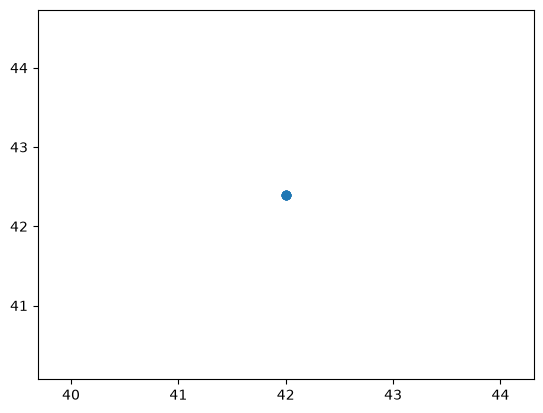

In [31]:
path = "../../Processed_data/"
# path = "../../ZAxisScan/"
# files = glob.glob(f"{path}proc_F_AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.root")
files = glob.glob(f"{path}proc_F_DJ_LGAD_50um_strip_10db_attenuation_LaserTuneScan_3_NEv1000_BV115000mV_Laser*pc_Temp16C_Zpos*_Xpos*_Ypos*00000.root")

# files = glob.glob(f"{path}F*--AC_LGAD_40um_strip_NEv*000_BV115000mV_Laser20pc_Temp16C_Zpos*_Xpos*00000.trc")

Z_range = [] # np.linspace(50.0, 50.8, 11)
X_range = [] # np.linspace(41.4, 41.7, 21)
Y_range = []
laser_tune = []

map_plot_x = []
map_plot_y = []
map_plot_z = []

for file in files:
    filename = file.split(path)[1]
    print(filename)
    x_pos = float(filename.split("Xpos")[1].split("_")[0])
    y_pos = float(filename.split("Ypos")[1].split("00000.root")[0])
    z_pos = float(filename.split("Zpos")[1].split("_")[0])
    lt = float(filename.split("mV_Laser")[1].split("pc_")[0])
    map_plot_x.append(x_pos)
    map_plot_y.append(y_pos)
    map_plot_z.append(z_pos)
    laser_tune.append(lt)
    X_range.append(x_pos)
    Y_range.append(y_pos)
    Z_range.append(z_pos)

Z_range = np.unique(Z_range)
X_range = np.unique(X_range)
Y_range = np.unique(Y_range)

# map_plot_x = np.sort(map_plot_x)
# map_plot_z = np.sort(map_plot_z)

plt.scatter(map_plot_x, map_plot_z)
plt.show()

fields = [
    'i_evt',
    # 'channel',
    # 'time',
    # 'baseline',
    'baseline_RMS',
    'noise',
    'amp',
    't_peak',
    'integral',
    # 'intfull',
    # 'risetime',
    # 'decaytime',
    # 'LP2_5',
    # 'LP2_10',
    # 'LP2_15',
    # 'LP2_20',
    # 'LP2_25',
    # 'LP2_30',
    # 'LP2_35',
    # 'LP2_40',
    # 'LP2_45',
    'LP2_50',
    # 'LP2_55',
    # 'LP2_60',
    # 'LP2_65',
    # 'LP2_70',
    # 'LP2_75',
    # 'LP2_80',
    # 'LP2_85',
    # 'LP2_90',
    # 'LP2_95',
    # 'LP2_100',
    # 'LP2_10mV',
    # 'LP2_20mV',
    # 'LP2_30mV',
    # 'LP2_50mV',
    # 'LP2_70mV',
    # 'LP2_90mV',
    # 'LP2_100mV',
    # 'LP2_120mV',
    # 'LP2_140mV',
    # 'LP2_160mV',
    # 'LP2_180mV',
    # 'LP2_200mV',
    # 'linear_RE_5',
    # 'linear_RE_10',
    # 'linear_RE_15',
    # 'linear_RE_20',
    # 'linear_RE_25',
    # 'linear_RE_30',
    # 'linear_RE_35',
    # 'linear_RE_40',
    # 'linear_RE_45',
    # 'linear_RE_50',
    # 'linear_RE_55',
    # 'linear_RE_60',
    # 'linear_RE_65',
    # 'linear_RE_70',
    # 'linear_RE_75',
    # 'linear_RE_80',
    # 'linear_RE_85',
    # 'linear_RE_90',
    # 'linear_RE_95',
    # 'linear_RE_100',
    # 'linear_RE__10mV',
    # 'linear_RE__20mV',
    # 'linear_RE__30mV',
    # 'linear_RE__50mV',
    # 'linear_RE__70mV',
    # 'linear_RE__90mV',
    # 'linear_RE__100mV',
    # 'linear_RE__120mV',
    # 'linear_RE__140mV',
    # 'linear_RE__160mV',
    # 'linear_RE__180mV',
    # 'linear_RE__200mV'
]
    

In [32]:
integral = {}
amp = {}
t_peak = {}
risetime = {}
timestamps = {}
baseline_RMS = {}
risetime = {}
channel = {}
time = {}

for f_i, f in enumerate(files):
    pulse = uproot.open(f)["pulse"].arrays(fields)
    l = f"pos_{map_plot_z[f_i]}_{map_plot_x[f_i]}_{map_plot_y[f_i]}_{laser_tune[f_i]}"
    # channel[l] = pulse["channel"]
    # time[l] = pulse["time"]
    t_peak[l] = pulse["t_peak"]
    integral[l] = pulse["integral"]
    # risetime[l] = pulse["risetime"]
    amp[l] = pulse["amp"]
    baseline_RMS[l] = pulse["baseline_RMS"]
    timestamps[l] = pulse["LP2_50"]
    del pulse

print(amp.keys())

dict_keys(['pos_42.4_42.0_106.0_20.0', 'pos_42.4_42.0_106.0_60.0', 'pos_42.4_42.0_106.0_40.0', 'pos_42.4_42.0_106.0_0.0', 'pos_42.4_42.0_106.0_100.0', 'pos_42.4_42.0_106.0_80.0'])


pos_42.4_42.0_106.0_20.0
[39.06195  39.06289  39.06383  39.06477  39.065712 39.06665  39.06759
 39.06853  39.06947  39.07041  39.07135  39.072292 39.07323  39.07417
 39.07511  39.07605  39.076992 39.07793  39.078873 39.07981  39.08075
 39.08169  39.08263  39.083572 39.08451  39.08545  39.08639  39.08733
 39.088272 39.08921  39.09015  39.09109  39.09203  39.09297  39.09391
 39.094852 39.09579  39.09673  39.09767  39.09861  39.099552 39.10049
 39.101433 39.10237  39.10331  39.10425  39.10519  39.106133 39.10707
 39.10801  39.10895  39.10989  39.110832 39.11177  39.11271  39.11365
 39.11459  39.115532 39.11647  39.117413 39.11835 ] [ 1  0  0  0  0  0  1  3  2  2  3  4  6  5  5  5  3 13  9 11  9 10 18 20
 22 27 14 17 24 20 25 18 16 23 22 16 16 14 17 14 11  8 10  6  3  5  6  1
  4  3  2  2  2  1  2  1  0  0  0  1]
pos_42.4_42.0_106.0_60.0


/tmp/ipykernel_1056450/632763101.py:29: OptimizeWarning: Covariance of the parameters could not be estimated
  params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), mean, std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )


[39.07706  39.078365 39.079666 39.08097  39.08227  39.083576 39.08488
 39.08618  39.087486 39.088787 39.09009  39.091396 39.092697 39.094
 39.095303 39.096607 39.09791  39.099213 39.100517 39.101818 39.103123
 39.104427 39.10573  39.107033 39.108334 39.10964  39.110943 39.112244
 39.11355  39.11485  39.116154 39.11746  39.11876  39.120064 39.121365
 39.12267  39.123974 39.125275 39.12658  39.12788  39.129185 39.13049
 39.13179  39.133095 39.134396 39.1357   39.137005 39.138306 39.13961
 39.14091  39.142216 39.14352  39.14482  39.146126 39.147427 39.14873
 39.150036 39.151337 39.15264  39.153942 39.155247] [ 1  0  0  1  0  1  1  1  1  1  0  2  3  0  5  7  2 10  4  7  4  8  9  8
 11 20 14 13 19 26 19 27 21 19 15 17 26 11 20 16 18 20  9 14 12  6  9  7
  7  6  3  4  3  1  1  2  1  1  0  1]
pos_42.4_42.0_106.0_40.0
[39.071938 39.073135 39.074333 39.07553  39.076725 39.077923 39.07912
 39.08032  39.081516 39.082714 39.083908 39.085106 39.086304 39.0875
 39.0887   39.089897 39.091095 39.09229

/tmp/ipykernel_1056450/1632829551.py:11: RuntimeWarning: overflow encountered in exp
  return A * np.exp(-1 * (x - mean)**2 / 2*(std))
/tmp/ipykernel_1056450/1632829551.py:11: RuntimeWarning: overflow encountered in multiply
  return A * np.exp(-1 * (x - mean)**2 / 2*(std))


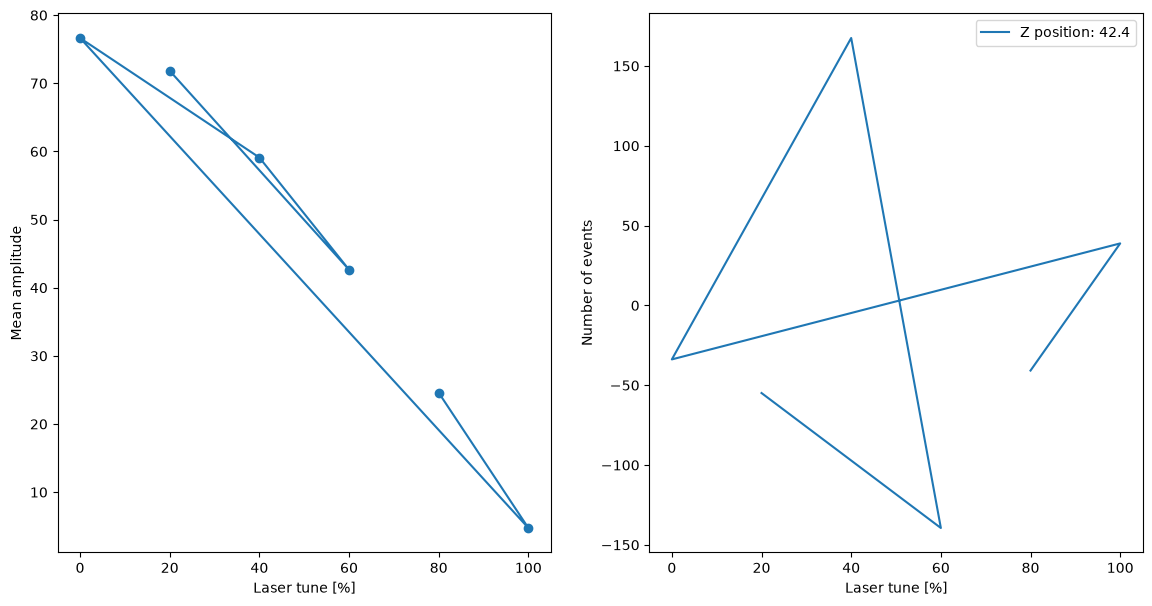

In [44]:
cols = 2
rows = 1
size = 7
channel = 5

fig, ax = plt.subplots(rows, cols, figsize = (size*cols, size*rows))
mean_amps = []
n_events = []
dt_res = []
for lt_i, lt in enumerate(laser_tune):
    for z_i, z in enumerate(Z_range):
        for x_i, x in enumerate(X_range):
            for y_i, y in enumerate(Y_range):
                l = f"pos_{z}_{x}_{y}_{lt}"
                print(l)
                # try:
                mask = (t_peak[l][:,7]>0.96)
                dt = timestamps[l][:,channel] - timestamps[l][:,7]
                mean_amps.append(np.mean(amp[l][mask][:,channel]))
                n_events.append(np.mean(dt[mask]))
                
                nbins = 60
                std = np.std(dt[mask])
                mean = np.mean(dt[mask])
                y, x = np.histogram(dt[mask], bins = nbins)
                x = np.array(x)
                y = np.array(y)
                print(x, y)
                params = curve_fit(gaus, x[0:nbins], y[0:nbins], p0=( np.max(y), mean, std)) # , bounds = bounds) # , p0=( np.mean(y), mean, np.std(hist[mask]) ) )
                # y_fit = [gaus(i, params[0][0], params[0][1], params[0][2]) for i in x[0:nbins]]
                # plt.show()
                dt_res.append(params[0][1])
                # except:
                #     mean_amps.append(0)
                #     n_events.append(0)
print(mean_amps)

sorting = np.argsort(laser_tune)
mean_amps = np.array(mean_amps)
n_events = np.array(n_events)

# params = curve_fit(gaus, X_range[mask], mean_amps[mask], p0 = (np.max(mean_amps[mask]), np.mean(X_range[mask]), 10))

print(len(laser_tune), len(mean_amps))

ax[0].plot(laser_tune, mean_amps, label = f"Z position: {z}", marker = "o")
ax[0].set_xlabel("Laser tune [%]")
ax[0].set_ylabel("Mean amplitude")

ax[1].plot(laser_tune, dt_res, label = f"Z position: {z}")
ax[1].set_xlabel("Laser tune [%]")
ax[1].set_ylabel("Number of events")

plt.legend()
plt.show()